# End-to-end: forecasting

This notebook runs one forecasting job from the question to the report: how many bikes will people rent tomorrow? It uses the same seven steps as every end-to-end notebook of the course, so you can compare the kinds of problems side by side.

*Session 12, end-to-end notebook. Course material, licence CC BY 4.0.*

## 1 The problem

A bike-sharing company plans each evening for the next day: how many mechanics to send out, how many bikes to repair overnight, how many vans to use. The planner asks: **how many bikes will be rented tomorrow?**

On the evening before, the planner knows the past (yesterday, last week), the calendar (is tomorrow a working day?) and the weather forecast for tomorrow. The order of the days matters, and the forecast must use only what is known on that evening. This is a **forecasting** problem. We turn it into a regression on what is known the evening before: first a linear regression, then the same model tuned, then gradient boosting.

## 2 Load the data

We import the libraries that every step uses. Each later step imports the scikit-learn parts it needs where it uses them.

In [1]:
# matplotlib and seaborn draw the static figures, plotly the one interactive figure;
# NumPy computes with arrays, pandas holds tables (DataFrames)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
# fetch_openml downloads a data set from the OpenML website
from sklearn.datasets import fetch_openml

# Wide tables stay on one line
pd.set_option("display.width", 150)
# A light grid and slightly larger fonts for every seaborn and matplotlib figure
sns.set_theme(style="whitegrid", font_scale=1.1)
# Plotly figures are saved in the notebook; plotly.js is loaded from the internet when the notebook is opened
pio.renderers.default = "plotly_mimetype+notebook_connected"

The Bike Sharing Demand data (Capital Bikeshare, Washington, D.C., 2011 and 2012) has one row per hour, in time order. `fetch_openml(data_id=42712, as_frame=True)` reads it from OpenML. The first call downloads about 1 MB and keeps a copy in `~/scikit_learn_data`, so later calls work offline.

In [2]:
# Load the bike data as a DataFrame; .frame keeps features and target in one table
try:
    bike_hours = fetch_openml(data_id=42712, as_frame=True).frame
# Without internet and without a saved copy, stop with a clear message
except Exception as error:
    raise RuntimeError("The bike data are not cached yet: run this cell once with internet access.") from error

# shape is (number of rows, number of columns)
print(bike_hours.shape)

(17379, 13)


One row is **one hour** at the bike-sharing system: how many bikes were rented in that hour, the calendar and the weather. The table below explains the columns we use. We build daily totals from them, and `count` summed over a day becomes the target. The other columns (`season`, `year`, `month`, `hour`, `holiday`, `feel_temp`, `windspeed`) are left out: the date and the working day already carry the calendar, and we keep the weather to three measures.

| Column | Meaning | Unit or values |
|---|---|---|
| `count` | bikes rented in this hour (summed per day, it is the target) | bikes, 1 to 977 |
| `weekday` | day of the week; a new value marks a new day | 0 = Sunday, 1 = Monday, …, 6 = Saturday |
| `workingday` | is the day neither a weekend day nor a public holiday? | "True" or "False" |
| `temp` | air temperature | degrees Celsius |
| `humidity` | relative humidity of the air | share from 0 to 1 |
| `weather` | the weather in this hour, in four groups | "clear", "misty", "rain", "heavy_rain" |


The data have no date column, but the rows are in time order and a new day starts whenever `weekday` changes. `ne(...shift())` marks those rows, and `cumsum()` counts them, which numbers the days from 1. Adding that number of days to 31 December 2010 gives the date. Then `groupby("date")["count"].sum()` adds up the hours to one total per day, and `asfreq("D")` checks that every day is present.

In [3]:
# True in the first hour of each day: weekday differs from the row before (shift(1) moves the column down by one)
is_new_day = bike_hours["weekday"].ne(bike_hours["weekday"].shift())
# cumsum counts the new days (1, 2, 3, …); added to 31 December 2010 as days, this gives the date
bike_hours["date"] = pd.Timestamp("2010-12-31") + pd.to_timedelta(is_new_day.cumsum(), unit="D")
# One total per day; asfreq("D") puts in a row with a missing value for any day that is absent
daily_rentals = bike_hours.groupby("date")["count"].sum().asfreq("D").rename("rentals")
print(daily_rentals.index.min().date(), "to", daily_rentals.index.max().date(), ";",
      len(daily_rentals), "days,", daily_rentals.isna().sum(), "missing")

2011-01-01 to 2012-12-31 ; 731 days, 0 missing


The same `groupby("date")` summarises the weather and the calendar of each day: the mean temperature and humidity, the number of hours with rain (`weather` is `"rain"` or `"heavy_rain"`), and whether the day is a working day. `agg(name=(column, function))` names each result column. `describe()` then summarises every daily column: its mean, spread and range.

In [4]:
# True for the hours with rain or heavy rain; isin checks membership in a list
bike_hours["is_rain_hour"] = bike_hours["weather"].isin(["rain", "heavy_rain"])
# The column holds the text "True" or "False"; == turns it into a real Boolean
bike_hours["is_working_day"] = bike_hours["workingday"] == "True"
# One row per day: mean temperature and humidity, number of rain hours, working day or not
daily_weather = bike_hours.groupby("date").agg(
    temperature=("temp", "mean"), humidity=("humidity", "mean"),
    rain_hours=("is_rain_hour", "sum"), is_working_day=("is_working_day", "first"))
# describe() summarises the number columns (count, mean, std, min, quartiles, max)
daily_weather.describe().round(2)

,temperature,humidity,rain_hours
count,731.00,731.00,731.00
mean,20.31,0.63,1.95
std,7.51,0.14,3.56
min,2.42,0.00,0.00
25%,13.82,0.52,0.00
50%,20.43,0.63,0.00
75%,26.87,0.73,2.00
max,35.33,0.97,21.00


## 3 Look at the data

A line plot of the daily totals shows the three parts of most time series: the trend, the seasons and the noise. The thicker line is the **rolling mean** over 30 days (`rolling(30, center=True).mean()`): each point is the average of the 30 days around it, so the daily noise is smoothed away.

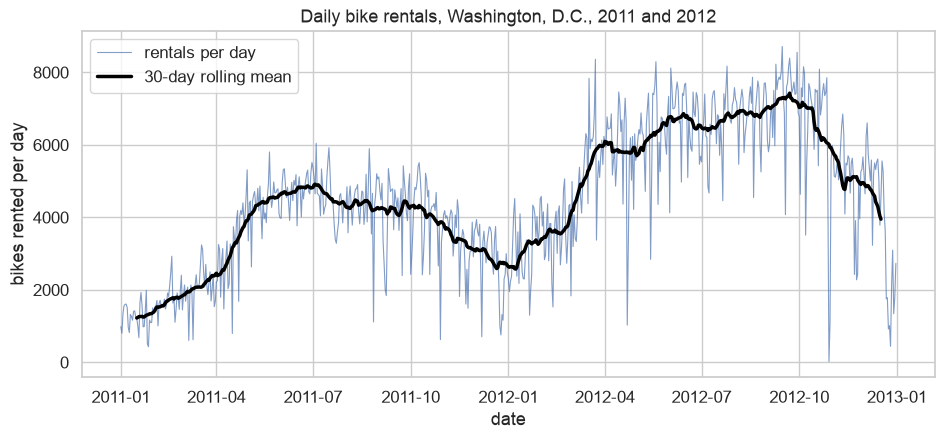

In [5]:
# The average of the 30 days around each day; center=True puts the window around the day, not before it
smoothed_rentals = daily_rentals.rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_rentals.index, daily_rentals, linewidth=0.8, alpha=0.7, label="rentals per day")
ax.plot(smoothed_rentals.index, smoothed_rentals, linewidth=2.5, color="black", label="30-day rolling mean")
ax.set_title("Daily bike rentals, Washington, D.C., 2011 and 2012")
ax.set_xlabel("date")
ax.set_ylabel("bikes rented per day")
ax.legend(loc="upper left")
plt.show()

**What do you see?** Demand grows from 2011 to 2012 (trend): the 30-day mean rises from about 1,300 bikes per day in January 2011 to above 7,000 in September 2012. It is high in summer and low in winter (seasons). Single days drop sharply (noise), for example on days of heavy rain or storms; the lowest day, at the end of October 2012, has almost no rentals. A good forecast follows the recent level and the season.

The seasons repeat with two periods: the week and the year. `groupby` with the weekday and the month gives the average rentals for each, one line per year. `dayofweek` numbers the days 0 = Monday to 6 = Sunday; `month` numbers the months 1 to 12.

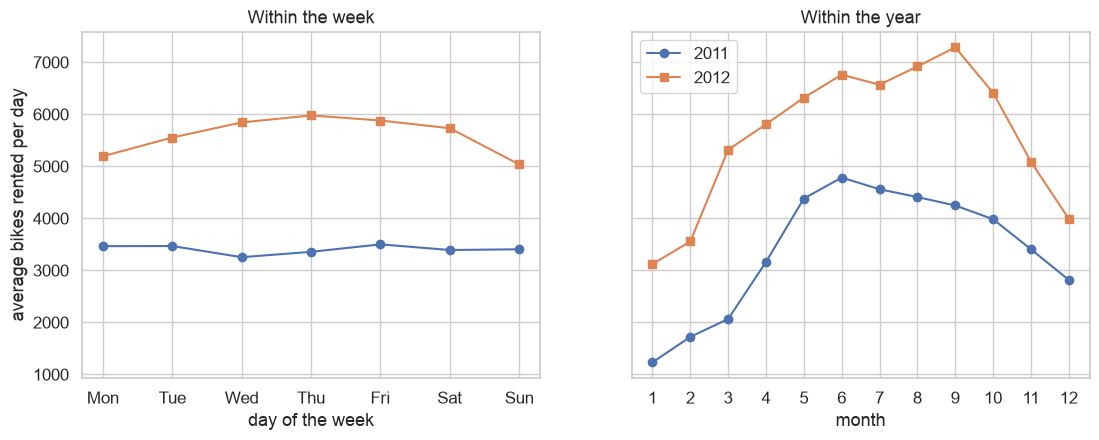

In [6]:
# Average rentals per (year, weekday) and per (year, month); unstack("year") makes one column per year
rentals_by_weekday = daily_rentals.groupby([daily_rentals.index.year.rename("year"),
                                            daily_rentals.index.dayofweek.rename("weekday")]).mean().unstack("year")
rentals_by_month = daily_rentals.groupby([daily_rentals.index.year.rename("year"),
                                          daily_rentals.index.month.rename("month")]).mean().unstack("year")

fig, (ax_week, ax_year) = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for year, marker in [(2011, "o"), (2012, "s")]:
    ax_week.plot(rentals_by_weekday.index, rentals_by_weekday[year], marker=marker, label=str(year))
    ax_year.plot(rentals_by_month.index, rentals_by_month[year], marker=marker, label=str(year))
ax_week.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax_week.set_title("Within the week")
ax_week.set_xlabel("day of the week")
ax_week.set_ylabel("average bikes rented per day")
ax_year.set_xticks(range(1, 13))
ax_year.set_xlabel("month")
ax_year.set_title("Within the year")
ax_year.legend()
plt.show()

**What do you see?** The year matters much more than the week. Within the year, rentals are lowest in January and highest from June to September; every month of 2012 is far above the same month of 2011. Within the week, the lines are almost flat: about 3,300 to 3,500 bikes per day in 2011, and from about 5,000 on Sunday to about 6,000 on Thursday in 2012. So a model must above all follow the current level, which `yesterday` and the 7-day mean in step 5 carry.

## 4 Split the data

In a time series we must never shuffle: the model would learn from days after the ones it predicts. We keep the last three months, October to December 2012, as the **test set** and train on everything before. Inside the training part, `TimeSeriesSplit` will choose the settings in step 6: each fold trains on the earlier days and validates on the days right after them.

In [7]:
# The first test day; every day before it is a training day
test_start = pd.Timestamp("2012-10-01")
print((daily_rentals.index < test_start).sum(), "training days,", (daily_rentals.index >= test_start).sum(), "test days")

639 training days, 92 test days


The plot shows the split on the time axis: the model learns from the blue part and is scored once on the orange part, which lies entirely after it.

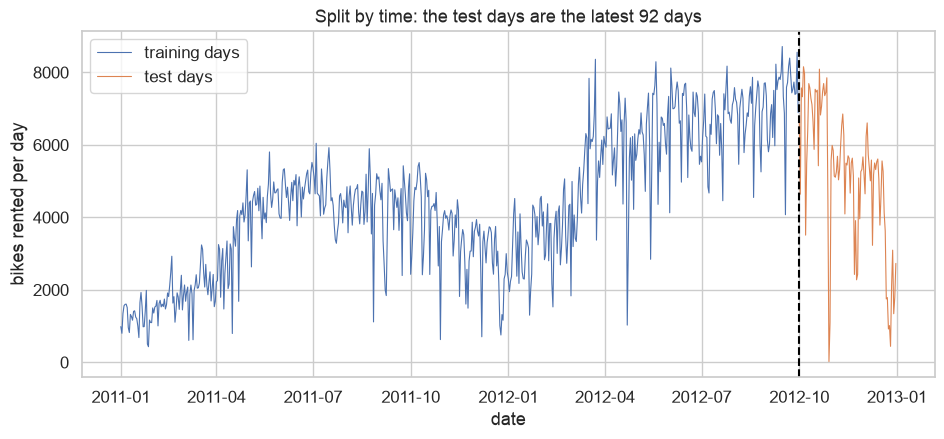

In [8]:
# Boolean masks for the two parts of the series
is_before_test = daily_rentals.index < test_start

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily_rentals.index[is_before_test], daily_rentals[is_before_test], linewidth=0.8, label="training days")
ax.plot(daily_rentals.index[~is_before_test], daily_rentals[~is_before_test], linewidth=0.8, label="test days")
# A dashed vertical line at the first test day
ax.axvline(test_start, color="black", linestyle="--")
ax.set_title("Split by time: the test days are the latest 92 days")
ax.set_xlabel("date")
ax.set_ylabel("bikes rented per day")
ax.legend(loc="upper left")
plt.show()

**What do you see?** The model learns from January 2011 to September 2012 and is scored on October to December 2012. The test months are the part of the year in which demand falls, from about 8,000 to below 1,000 bikes per day, and they hold the deepest single drop of the two years. This is a harder test than a random sample of days would be, and it is the honest one: the planner also forecasts days that come after all the data.

## 5 Process the data

A regression model needs a table with features X and a target y. We build it from the series: each row is one day, the target is that day's rentals, and the features are what is known on the evening before. `shift(k)` moves the series k days down, so each row sees the value of k days earlier.

- `yesterday`: the rentals of the day before (`shift(1)`);
- `same_day_last_week`: the rentals seven days before (`shift(7)`);
- `mean_last_7_days`: the average of the seven days up to yesterday (`shift(1).rolling(7).mean()`);
- `weekday` and `is_working_day`: known in advance from the calendar;
- `temperature`, `humidity` and `rain_hours` of the day itself. The planner would read them from the weather forecast; the data hold the measured weather, which we use in its place.

The first seven days have no full week of history, so `dropna()` removes them.

In [9]:
# One row per day: the target, three lag features, the weekday and the day's weather and calendar
forecast_table = pd.DataFrame({
    "rentals": daily_rentals,
    "yesterday": daily_rentals.shift(1),
    "same_day_last_week": daily_rentals.shift(7),
    # shift(1) first, so the mean ends yesterday and never contains the day we forecast
    "mean_last_7_days": daily_rentals.shift(1).rolling(7).mean(),
    "weekday": daily_rentals.index.dayofweek,
}).join(daily_weather).dropna()
# join adds the weather columns by date; dropna removes the first 7 days, which lack a full week of history
print(len(forecast_table), "days with all features")
# One row per number column: mean, spread and range; .T turns the table so each column is a row
forecast_table.describe().round(1).T

724 days with all features


,count,mean,std,min,25%,50%,75%,max
rentals,724.0,4534.9,1921.1,22.0,3214.0,4566.0,5987.5,8714.0
yesterday,724.0,4533.2,1923.2,22.0,3214.0,4566.0,5987.5,8714.0
same_day_last_week,724.0,4530.6,1926.1,22.0,3214.0,4566.0,5987.5,8714.0
mean_last_7_days,724.0,4531.7,1739.2,1022.7,3348.3,4473.6,6123.8,7988.0
weekday,724.0,3.0,2.0,0.0,1.0,3.0,5.0,6.0
temperature,724.0,20.4,7.5,2.4,14.0,20.6,26.9,35.3
humidity,724.0,0.6,0.1,0.0,0.5,0.6,0.7,1.0
rain_hours,724.0,2.0,3.6,0.0,0.0,0.0,2.0,21.0


Why should yesterday help? A scatter plot of yesterday's rentals against today's rentals, over the training days, shows how closely the two follow each other.

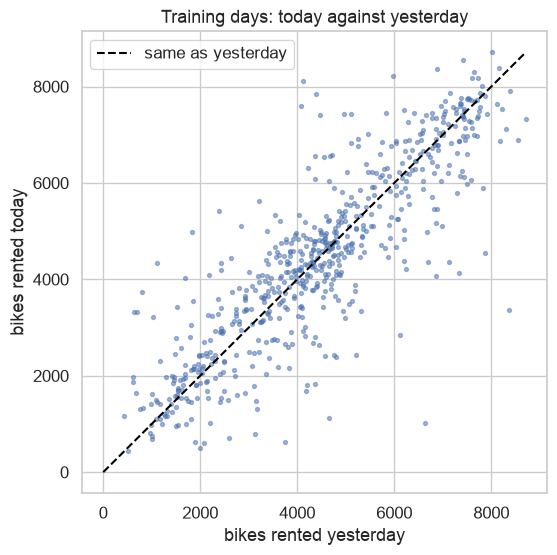

correlation of yesterday and today: 0.86


In [10]:
# Only the days before the test period, so the plot uses no test data
training_rows = forecast_table[forecast_table.index < test_start]

fig, ax = plt.subplots(figsize=(6, 6))
# One point per day: yesterday's rentals on the x-axis, today's rentals on the y-axis
ax.scatter(training_rows["yesterday"], training_rows["rentals"], s=8, alpha=0.5)
# The dashed diagonal: points on it are days with exactly yesterday's rentals
largest_day = training_rows["rentals"].max()
ax.plot([0, largest_day], [0, largest_day], linestyle="--", color="black", label="same as yesterday")
ax.set_title("Training days: today against yesterday")
ax.set_xlabel("bikes rented yesterday")
ax.set_ylabel("bikes rented today")
ax.legend(loc="upper left")
plt.show()
# corr() is the Pearson correlation: 1 means the points lie exactly on a rising line
print("correlation of yesterday and today:", round(training_rows["yesterday"].corr(training_rows["rentals"]), 2))

**What do you see?** Most days lie close to the dashed diagonal: today's rentals are close to yesterday's (correlation 0.86). Some days lie far below it, with many fewer bikes than the day before. These are mostly days of bad weather, which yesterday's value cannot know; the weather features of the day can help there.

Now we split the table by date. `X` holds the features and `y` the target.

In [11]:
# The eight features, all known on the evening before the day we forecast
feature_columns = ["yesterday", "same_day_last_week", "mean_last_7_days", "weekday",
                   "is_working_day", "temperature", "humidity", "rain_hours"]
# True for the rows before October 2012
is_training_day = forecast_table.index < test_start
X_train, y_train = forecast_table.loc[is_training_day, feature_columns], forecast_table.loc[is_training_day, "rentals"]
X_test, y_test = forecast_table.loc[~is_training_day, feature_columns], forecast_table.loc[~is_training_day, "rentals"]
print(len(X_train), "training days,", len(X_test), "test days")

632 training days, 92 test days


The linear models of step 6 need two more steps, so a `ColumnTransformer` treats each kind of column with its own step:

- **Numbers** (the three lags, `temperature`, `humidity`, `rain_hours`) are on very different scales: thousands of bikes, degrees, a share below 1. `StandardScaler` gives each a mean of 0 and a standard deviation of 1, so the penalty of ridge regression treats them alike.
- **Calendar** (`weekday`, `is_working_day`). For a linear model, Saturday (5) is not "five times Monday" (0). `OneHotEncoder` gives each weekday its own 0/1 column, so each gets its own weight.

The transformer learns the means and the categories from the training days only, when it is fitted. Trees need none of this: they split on thresholds, so scale does not matter.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Which columns are numbers and which are calendar categories
numeric_columns = ["yesterday", "same_day_last_week", "mean_last_7_days", "temperature", "humidity", "rain_hours"]
calendar_columns = ["weekday", "is_working_day"]

# StandardScaler gives each number a mean of 0 and a standard deviation of 1;
# OneHotEncoder turns each category value into its own 0/1 column
# (handle_unknown="ignore": a value never seen in training becomes all zeros instead of an error)
linear_preprocessing = ColumnTransformer([
    ("numbers", StandardScaler(), numeric_columns),
    ("calendar", OneHotEncoder(handle_unknown="ignore"), calendar_columns),
])
# fit_transform learns the means and categories from the training days and returns the processed array
print(linear_preprocessing.fit_transform(X_train).shape)

(632, 15)


The six numbers stay six columns, the seven weekdays become seven 0/1 columns and the working day two, so the 8 features become 15 columns.

## 6 Run the pipeline

We start with the most common model, score it, and then improve it one step at a time: a linear regression on the lag, calendar and weather features, the same model tuned with a grid search, and then a more flexible model. The five decisions of the three models:

| Decision | Linear regression | Ridge regression | Gradient boosting |
|---|---|---|---|
| Data | one row per day before October 2012: lags, the 7-day mean, the calendar and the weather as X, the day's rentals as y | the same | the same |
| Model | a weighted sum of the 15 processed columns | the same | a sum of many small regression trees |
| Loss function | squared error | squared error plus an L2 penalty of strength `alpha` | absolute error (`loss="absolute_error"`), the same measure as the evaluation |
| Optimizer | a formula (least squares, solved exactly) | a formula (a linear system solved exactly) | gradient boosting: each new tree fits the gradient of the loss |
| Evaluation | MAE and RMSE on the last three months | the same; `GridSearchCV` with `TimeSeriesSplit` chooses `alpha` | the same; `GridSearchCV` with `TimeSeriesSplit` chooses the tree settings |

Every model is scored in the same way, with two measures from `sklearn.metrics`:

- **MAE** (`mean_absolute_error(y_test, y_predicted)`): the average miss, in bikes per day.
- **RMSE** (`root_mean_squared_error(y_test, y_predicted)`): the square root of the average squared miss, also in bikes per day. Large misses count more than in the MAE.

Each model cell forecasts the test days, prints both measures and plots its forecast against the actual rentals. Step 7 puts all forecasts in one plot.

### 6.1 Linear regression

`LinearRegression` learns one weight per processed column and forecasts their weighted sum. A `Pipeline` chains the preprocessing of step 5 and the model, so `fit` learns both from the training days, and `predict` applies both to new rows.

linear regression: MAE 743, RMSE 1132 bikes per day


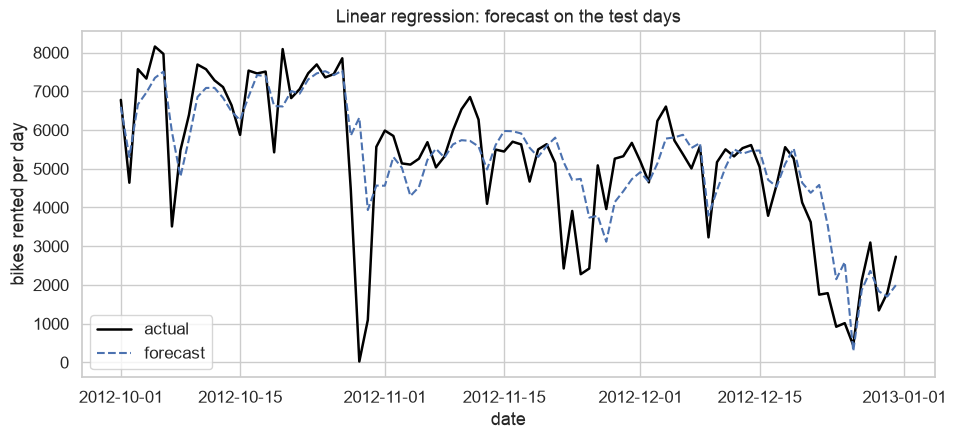

In [13]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.pipeline import Pipeline

# A Pipeline runs its steps in order: first the preprocessing of step 5, then the model
linear_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("linear", LinearRegression())])
# fit learns the preprocessing and the weights from the training days
linear_pipeline.fit(X_train, y_train)

# Forecast the rentals of every test day; the Series keeps the dates as its index
# y_predicted_linear: the predicted y (rentals) of the linear model
y_predicted_linear = pd.Series(linear_pipeline.predict(X_test), index=X_test.index)
# Each metric compares the actual rentals with the forecasts, in bikes per day
linear_scores = {"model": "linear regression",
                 "MAE": mean_absolute_error(y_test, y_predicted_linear),
                 "RMSE": root_mean_squared_error(y_test, y_predicted_linear)}
print(f"linear regression: MAE {linear_scores['MAE']:.0f}, RMSE {linear_scores['RMSE']:.0f} bikes per day")

# The forecast against the actual rentals on the test days
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y_test.index, y_test, color="black", linewidth=1.8, label="actual")
ax.plot(y_predicted_linear.index, y_predicted_linear, linestyle="--", label="forecast")
ax.set_title("Linear regression: forecast on the test days")
ax.set_xlabel("date")
ax.set_ylabel("bikes rented per day")
ax.legend(loc="lower left")
plt.show()

**What do you see?** Linear regression misses the daily rentals by 743 bikes on average (MAE). The RMSE, 1,132 bikes, is much larger than the MAE: a few days have very large misses, and the RMSE weights them more. The plot shows the largest one: at the end of October rentals fall to almost 0, and the forecast stays near 6,000. On most other days the dashed forecast follows the actual line, often one day late after a sharp change.

### 6.2 Tune the linear model with a grid search

**Regularisation** keeps a model from fitting noise in the training days: the loss gets an extra term that grows with the size of the weights, so a large weight must earn its place. Ridge regression is linear regression with this penalty (the L2 penalty, the sum of the squared weights). Its strength `alpha` is a **hyperparameter**: a setting we choose, which the model does not learn from the data. A larger `alpha` is a stronger penalty and smaller weights; `alpha` near 0 is plain linear regression. Too small risks overfitting, too large underfits, so we try several values. `GridSearchCV` tries each value in a list and keeps the best one. It scores each value on parts of the training days only, so the test days stay unseen until we score the winner.

- `{"ridge__alpha": [0.1, 1, 10, 100]}` is the grid: `ridge__alpha` means the argument `alpha` of the step named `ridge`.
- `cv=TimeSeriesSplit(n_splits=5)` cuts the training days into six pieces in time order. Fold 1 trains on piece 1 and validates on piece 2, fold 2 trains on pieces 1 and 2 and validates on piece 3, and so on. A fold never validates on days before its training days. A plain `cv=5` would shuffle the days and let the model learn from the future.
- `scoring="neg_mean_absolute_error"` chooses by MAE. It is negated because scikit-learn always maximizes a score.
- After the search, `best_params_` is the chosen value and `best_estimator_` is the pipeline refitted with it on all training days.

 alpha  validation MAE
   0.1           589.0
   1.0           587.0
  10.0           585.0
 100.0           684.0
chosen: {'ridge__alpha': 10}
ridge regression, tuned: MAE 742, RMSE 1122 bikes per day


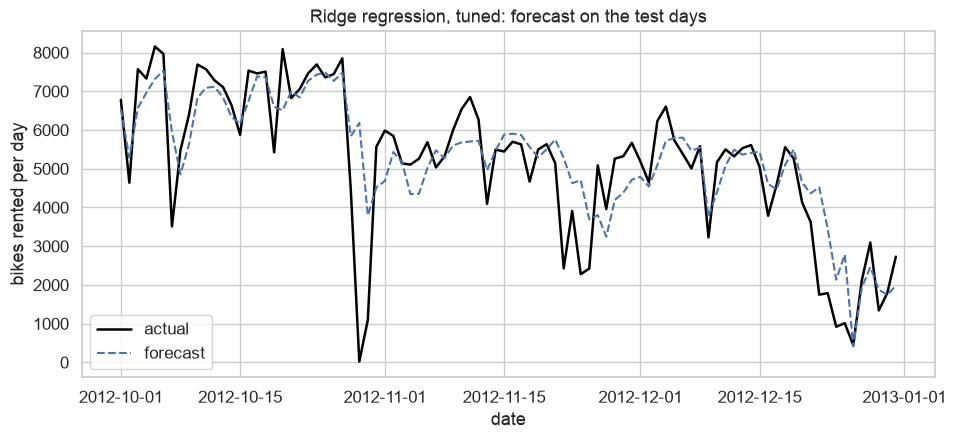

In [14]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# The same pipeline, with Ridge (linear regression with a penalty) as the model
ridge_pipeline = Pipeline([("preprocessing", linear_preprocessing), ("ridge", Ridge())])
# Five folds in time order: each validates on the days right after its training days
time_folds = TimeSeriesSplit(n_splits=5)
ridge_search = GridSearchCV(ridge_pipeline, {"ridge__alpha": [0.1, 1, 10, 100]}, cv=time_folds,
                            scoring="neg_mean_absolute_error")
# fit runs the whole search, then refits the best pipeline on all training days
ridge_search.fit(X_train, y_train)

# cv_results_ holds the mean validation score of every value; the minus sign turns it back into an MAE
ridge_validation = pd.DataFrame({"alpha": ridge_search.cv_results_["param_ridge__alpha"],
                                 "validation MAE": (-ridge_search.cv_results_["mean_test_score"]).round(0)})
print(ridge_validation.to_string(index=False))
print("chosen:", ridge_search.best_params_)
# best_estimator_ is the refitted best pipeline; only now do we score it on the test days

# Forecast the rentals of every test day; the Series keeps the dates as its index
y_predicted_ridge = pd.Series(ridge_search.best_estimator_.predict(X_test), index=X_test.index)
# Each metric compares the actual rentals with the forecasts, in bikes per day
ridge_scores = {"model": "ridge regression, tuned",
                 "MAE": mean_absolute_error(y_test, y_predicted_ridge),
                 "RMSE": root_mean_squared_error(y_test, y_predicted_ridge)}
print(f"ridge regression, tuned: MAE {ridge_scores['MAE']:.0f}, RMSE {ridge_scores['RMSE']:.0f} bikes per day")

# The forecast against the actual rentals on the test days
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y_test.index, y_test, color="black", linewidth=1.8, label="actual")
ax.plot(y_predicted_ridge.index, y_predicted_ridge, linestyle="--", label="forecast")
ax.set_title("Ridge regression, tuned: forecast on the test days")
ax.set_xlabel("date")
ax.set_ylabel("bikes rented per day")
ax.legend(loc="lower left")
plt.show()

**What do you see?** The validation MAE is almost the same for `alpha` from 0.1 to 10 (589 to 585 bikes) and much worse for 100 (684): a strong penalty pulls all weights, also that of `yesterday`, towards 0. The search chose `alpha = 10`. On the test days the MAE moves from 743 to 742 bikes. With 632 training days and 15 columns, the weights are already stable, so a penalty has little to correct.

### 6.3 A more flexible model: gradient boosting

Gradient boosting adds many small regression trees. A tree can split on combinations, for example "a working day **and** more than three hours of rain", which a weighted sum cannot. All features are numbers and trees need no scaling, so this pipeline has the model step only. `loss="absolute_error"` makes the trees minimize the same measure we report, and `max_iter=200` sets the number of trees.

The grid tries two learning rates (how much each new tree corrects) and two tree sizes (`max_leaf_nodes`, the most leaves one tree may have), four settings in all, with the same time-ordered folds. Both are hyperparameters, and both are a form of regularisation: a small learning rate and small trees make each step cautious, so the model fits the training days less tightly.

chosen: {'boosting__learning_rate': 0.1, 'boosting__max_leaf_nodes': 7} ; validation MAE: 927
gradient boosting, tuned: MAE 761, RMSE 1099 bikes per day


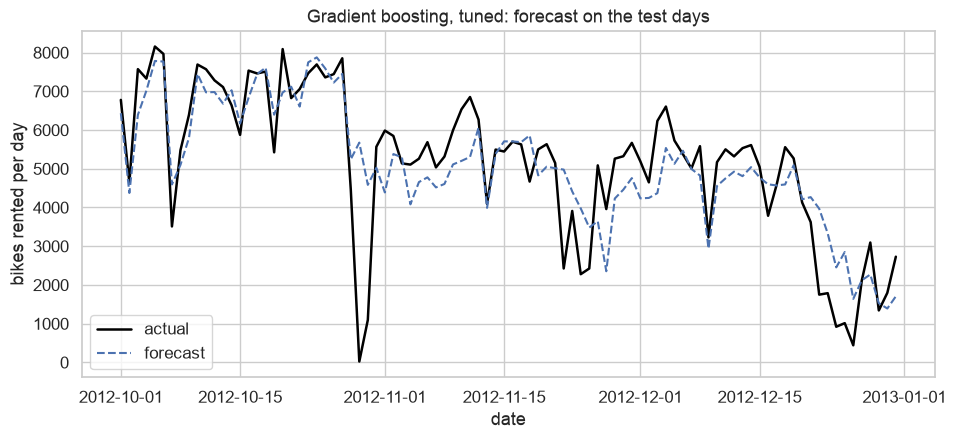

In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Trees need no scaling or one-hot columns, so the pipeline has the model step only
boosting_pipeline = Pipeline([
    ("boosting", HistGradientBoostingRegressor(loss="absolute_error", max_iter=200, random_state=0)),
])
# 2 learning rates × 2 tree sizes = 4 settings to try, with the time-ordered folds of 6.2
boosting_grid = {"boosting__learning_rate": [0.03, 0.1], "boosting__max_leaf_nodes": [7, 15]}
boosting_search = GridSearchCV(boosting_pipeline, boosting_grid, cv=time_folds, scoring="neg_mean_absolute_error")
boosting_search.fit(X_train, y_train)
print("chosen:", boosting_search.best_params_, "; validation MAE:", round(-boosting_search.best_score_))

# Forecast the rentals of every test day; the Series keeps the dates as its index
y_predicted_boosting = pd.Series(boosting_search.best_estimator_.predict(X_test), index=X_test.index)
# Each metric compares the actual rentals with the forecasts, in bikes per day
boosting_scores = {"model": "gradient boosting, tuned",
                 "MAE": mean_absolute_error(y_test, y_predicted_boosting),
                 "RMSE": root_mean_squared_error(y_test, y_predicted_boosting)}
print(f"gradient boosting, tuned: MAE {boosting_scores['MAE']:.0f}, RMSE {boosting_scores['RMSE']:.0f} bikes per day")

# The forecast against the actual rentals on the test days
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(y_test.index, y_test, color="black", linewidth=1.8, label="actual")
ax.plot(y_predicted_boosting.index, y_predicted_boosting, linestyle="--", label="forecast")
ax.set_title("Gradient boosting, tuned: forecast on the test days")
ax.set_xlabel("date")
ax.set_ylabel("bikes rented per day")
ax.legend(loc="lower left")
plt.show()

**What do you see?** The grid search chose a learning rate of 0.1 and 7 leaves per tree. Gradient boosting is worse than ridge regression on the time-ordered validation (MAE 927 against 585 bikes) and also on the test days (761 against 742). Its RMSE is a little lower (1,099 against 1,122), so it has fewer very large misses. The reason for the weak validation score: the early folds train on 2011 only and validate on the busier days of 2012. A tree can only forecast values in the range it saw in training, while a weighted sum of `yesterday` and the 7-day mean rises with the level.

## 7 Report the results

One table puts the scores of the three models from section 6 side by side, in the order we built them. Then we look at the forecasts on the time axis, and we ask how sure these numbers are.

In [16]:
# One row per model, built from the score dictionaries of 6.1, 6.2 and 6.3
test_results = pd.DataFrame([linear_scores, ridge_scores, boosting_scores]).set_index("model").round(0)
test_results

,MAE,RMSE
model,,
linear regression,743.0,1132.0
"ridge regression, tuned",742.0,1122.0
"gradient boosting, tuned",761.0,1099.0


A plot of the test months shows the forecasts of 6.1 to 6.3 against the actual rentals, day by day. This is the one interactive figure of the notebook: move the mouse over it to read the actual rentals and the three forecasts of a day, and click a name in the legend to hide or show its line.

In [17]:
# The test forecasts of 6.1, 6.2 and 6.3 in one dictionary, so the cells below can loop over them
y_predicted_by_model = {"linear regression": y_predicted_linear,
                        "ridge regression, tuned": y_predicted_ridge,
                        "gradient boosting, tuned": y_predicted_boosting}

# go.Figure is an empty plotly figure; each go.Scatter adds one line, and hovering shows its values
fig = go.Figure()
# .tolist() passes plain lists, which every plotly viewer can read
fig.add_trace(go.Scatter(x=y_test.index.tolist(), y=y_test.tolist(), name="actual", line=dict(color="black", width=3)))
for (model_name, y_predicted), dash in zip(y_predicted_by_model.items(), ["dot", "dashdot", "dash"]):
    fig.add_trace(go.Scatter(x=y_predicted.index.tolist(), y=y_predicted.round(0).tolist(), name=model_name, line=dict(dash=dash)))
# hovermode="x unified" shows the values of all lines for the date under the mouse
fig.update_layout(title="Forecasts against the actual rentals, October to December 2012",
                  xaxis_title="date", yaxis_title="bikes rented per day", hovermode="x unified",
                  template="plotly_white", width=950, height=450, legend=dict(x=0.01, y=0.01))
fig.show()

**What do you see?** All three forecasts follow the actual rentals closely, and the lines of linear and ridge regression lie almost on top of each other. On 29 October 2012 rentals fall to 22 bikes: Hurricane Sandy reached Washington. All models forecast thousands of bikes for that day, although they see its rain hours: the training days hold no storm like it. After large drops the forecasts react one day late, because `yesterday` is their strongest feature.

The **error** of a day is the actual rentals minus the forecast: above 0, the model forecast too few bikes; below 0, too many. Plotting it over time shows whether the misses are random or come in runs. Linear regression is left out because its errors are almost the same as those of tuned ridge.

ridge regression, tuned: largest miss 6160 bikes on 2012-10-29
    mean error -92 bikes, correlation with the day before 0.40
gradient boosting, tuned: largest miss 5653 bikes on 2012-10-29
    mean error 78 bikes, correlation with the day before 0.50


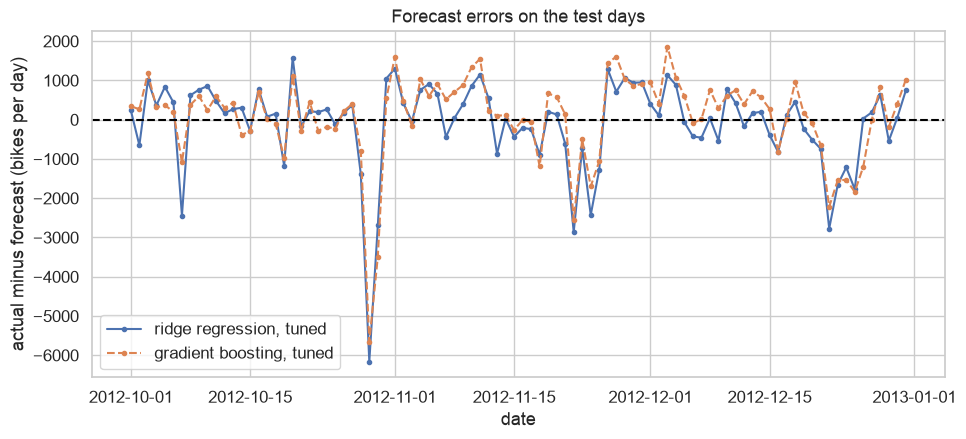

In [18]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for model_name, style in [("ridge regression, tuned", "-"), ("gradient boosting, tuned", "--")]:
    # Actual minus forecast, one value per test day
    forecast_errors = y_test - y_predicted_by_model[model_name]
    ax.plot(forecast_errors.index, forecast_errors, linestyle=style, marker=".", label=model_name)
    # idxmax of the absolute error is the date of the largest miss
    print(f"{model_name}: largest miss {forecast_errors.abs().max():.0f} bikes on {forecast_errors.abs().idxmax().date()}")
    # The mean error shows a bias (too low on average if above 0); autocorr() is the correlation of
    # each day's error with the error of the day before: near 0 for independent errors
    print(f"    mean error {forecast_errors.mean():.0f} bikes, correlation with the day before {forecast_errors.autocorr():.2f}")
# A dashed line at 0: a perfect forecast
ax.axhline(0, color="black", linestyle="--")
ax.set_xlabel("date")
ax.set_title("Forecast errors on the test days")
ax.set_ylabel("actual minus forecast (bikes per day)")
ax.legend(loc="lower left")
plt.show()

**What do you see?** The largest miss of both models is the storm day, 29 October (6,160 bikes for ridge, 5,653 for gradient boosting). The errors come in runs: in early November and around 1 December both models forecast too few bikes for many days in a row, and around Thanksgiving (22 November) and in the Christmas week too many. The correlation of each day's error with the error of the day before is 0.40 for ridge and 0.50 for gradient boosting, far from 0. On average ridge forecasts 92 bikes too many and gradient boosting 78 too few.

### 7.1 How sure is each score?

The test set is one sample of 92 days. Another autumn would give slightly different scores. A **95% confidence interval** shows how far a score could move for that reason: over many test sets, 95 of 100 such intervals contain the model's true score.

The MAE has no simple formula for its interval, so we use the **bootstrap**. The fitted models stay fixed; only the test days are drawn again, and the MAE is computed on each new sample. Repeated 1,000 times, the middle 95% of the 1,000 MAEs, from the 2.5th to the 97.5th percentile, is the interval.

**Why blocks of days?** The plain bootstrap draws single rows with replacement and assumes that every row is an independent draw. The errors of neighbouring days are not independent: the plot above shows that they come in runs, because a model that is too low on Monday is often too low on Tuesday as well. A plain bootstrap breaks these runs apart, so it shows too little variation and gives intervals that are too narrow. The **moving-block bootstrap** draws **blocks of 7 consecutive test days** instead, with replacement, and puts 14 blocks one after the other (14 × 7 = 98 days, cut to 92). Each block keeps a whole week of neighbouring errors together, with its weekday pattern.

In [19]:
# 1,000 resamples; each resample is 14 blocks of 7 consecutive test days, cut to 92 days
rng = np.random.default_rng(0)
n_resamples = 1000
n_test_days = len(y_test)
block_length = 7
n_blocks = int(np.ceil(n_test_days / block_length))
# The first day of each block: any position from which 7 days still fit into the test period
block_starts = rng.integers(0, n_test_days - block_length + 1, size=(n_resamples, n_blocks))
# Add 0, 1, …, 6 to each start, lay the blocks one after the other, keep the first 92 positions
resampled_days = (block_starts[:, :, None] + np.arange(block_length)).reshape(n_resamples, -1)[:, :n_test_days]

# For comparison: the plain bootstrap, which draws 92 single days with replacement
single_days = rng.integers(0, n_test_days, size=(n_resamples, n_test_days))

# The MAE of every model on every resample; the models are never refitted
actual_rentals = y_test.to_numpy()
block_mae = {}
interval_rows = []
for model_name, y_predicted in y_predicted_by_model.items():
    forecast_values = y_predicted.to_numpy()
    block_mae[model_name] = np.array([mean_absolute_error(actual_rentals[days], forecast_values[days])
                                      for days in resampled_days])
    single_mae = np.array([mean_absolute_error(actual_rentals[days], forecast_values[days]) for days in single_days])
    # The interval: the 2.5th and the 97.5th percentile of the 1,000 MAEs
    block_lower, block_upper = np.percentile(block_mae[model_name], [2.5, 97.5])
    single_lower, single_upper = np.percentile(single_mae, [2.5, 97.5])
    interval_rows.append({"model": model_name,
                          "MAE": mean_absolute_error(actual_rentals, forecast_values),
                          "95% CI from": block_lower, "95% CI to": block_upper,
                          "plain bootstrap from": single_lower, "plain bootstrap to": single_upper})
mae_intervals = pd.DataFrame(interval_rows).set_index("model").round(0)
mae_intervals

,MAE,95% CI from,95% CI to,plain bootstrap from,plain bootstrap to
model,,,,,
linear regression,743.0,537.0,1016.0,587.0,935.0
"ridge regression, tuned",742.0,543.0,1003.0,593.0,933.0
"gradient boosting, tuned",761.0,580.0,1012.0,624.0,929.0


**What do you see?** The intervals are wide: tuned ridge regression has an MAE of 742 bikes per day, with a 95% interval of 543 to 1,003. The intervals are not symmetric: they reach further up than down, because a resample that draws the storm week more than once has a much larger MAE. The plain bootstrap gives about 593 to 933 for the same model, about a quarter narrower; it ignores the runs of errors and so shows more certainty than the data allow. The three intervals overlap almost completely.

### 7.2 Is the next model really better? The interval of the difference

To compare two models, we do not compare their two intervals. A comparison of two classmates shows why.

> Anna and Ben take the same exam every year, and the exam is harder in some years than in others. Anna's scores range from 70 to 90, and Ben's from 75 to 95, so the ranges overlap. But in every year, on the same exam, Ben scores about 5 points more than Anna. Is Ben better? Yes. The overlap only shows that the exams vary in difficulty. To compare them, you compare them on the same exam, which is the difference.

Our models are in the same situation: all of them are scored on the **same** test days. A resample with many calm weeks lowers the MAE of every model; a resample with the storm week raises it for every model. This shared luck makes each interval wide, and it cancels when we subtract one score from the other.

So we compute the **gain** of each step on every resample, with the same blocks of days for both models: the MAE of the earlier model minus the MAE of the later one. A positive gain means the later model misses fewer bikes. The middle 95% of the 1,000 gains is the **95% interval of the difference**:

- the interval lies above 0: the later model is better, by about the amount the interval shows; below 0: it is worse;
- the interval contains 0: on this test set we cannot tell the two models apart.

In [20]:
# Each step of section 6, as (short label, earlier model, later model)
steps = [("linear → ridge", "linear regression", "ridge regression, tuned"),
         ("ridge → boosting", "ridge regression, tuned", "gradient boosting, tuned")]

gain_rows = []
for label, earlier, later in steps:
    # The same resampled blocks for both models, so every gain compares them on the same days
    gains = block_mae[earlier] - block_mae[later]
    lower, upper = np.percentile(gains, [2.5, 97.5])
    gain_rows.append({"step": label,
                      "gain in MAE": (mean_absolute_error(actual_rentals, y_predicted_by_model[earlier])
                                      - mean_absolute_error(actual_rentals, y_predicted_by_model[later])),
                      "95% CI from": lower, "95% CI to": upper})
mae_gains = pd.DataFrame(gain_rows).set_index("step").round(1)
mae_gains

,gain in MAE,95% CI from,95% CI to
step,,,
linear → ridge,1.1,-15.6,20.4
ridge → boosting,-18.6,-110.4,82.9


A histogram of the 1,000 gains of each step shows the same thing as a picture. The two solid lines mark the interval, the dashed line a gain of 0, "no difference".

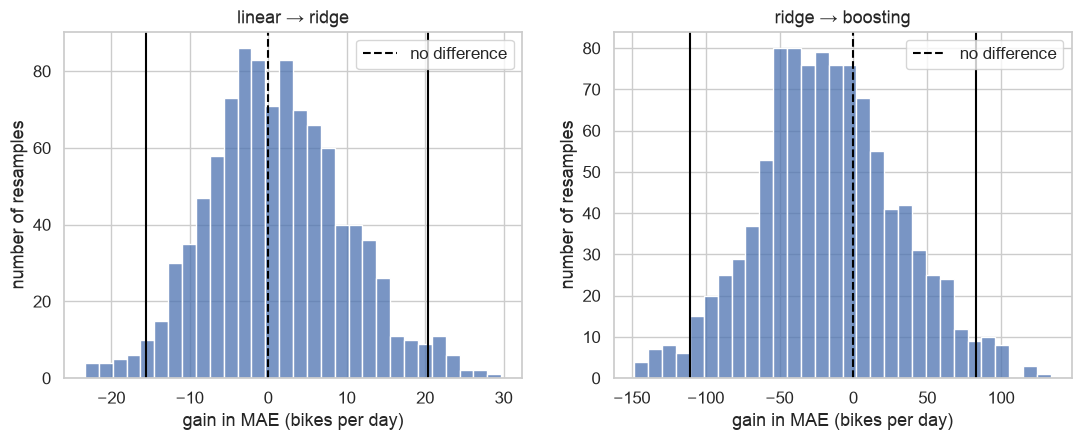

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (label, earlier, later) in zip(axes, steps):
    gains = block_mae[earlier] - block_mae[later]
    # sns.histplot counts the gains in 30 bars
    sns.histplot(gains, bins=30, ax=ax)
    # The 95% interval as two solid lines, the value 0 as a dashed line
    for bound in np.percentile(gains, [2.5, 97.5]):
        ax.axvline(bound, color="black")
    ax.axvline(0, color="black", linestyle="--", label="no difference")
    ax.set_title(label)
    ax.set_xlabel("gain in MAE (bikes per day)")
    ax.legend()
    ax.set_ylabel("number of resamples")
plt.show()

**What do you see?** Left: tuning the ridge penalty gains 1.1 bikes per day, with an interval of −15.6 to 20.4 that contains 0, so the tuned and the untuned model cannot be told apart. Right: gradient boosting misses 18.6 bikes per day **more** than tuned ridge, but the interval, −110.4 to 82.9, also contains 0: on these 92 days we cannot tell the two models apart. This interval is still less than half as wide as each separate interval in 7.1, because the shared luck of the storm week cancels in the difference. When two models cannot be told apart, we choose the simpler one: ridge regression, which was also much better on the time-ordered validation.

**The assumption that matters here.** Every bootstrap assumes that the pieces it draws are independent of each other. Single days are not: their errors are correlated with the day before (0.40 and 0.50), which is why we draw blocks of 7 days. The blocks must then be roughly independent, and 92 days hold only 13 full weeks, so the intervals are rough. They also describe autumns like this one only: all test days come from one season with one storm, and a forecast for the summer may miss by a different amount.

### 7.3 Use the model on a new input

Imagine the planner has deployed the chosen model, tuned ridge regression. On the evening of the last day in the data, the planner wants the forecast for the next day. The model needs one row with the eight features of `X_train`, all known that evening: the rentals of the past days from the series, the calendar, and the weather forecast for the next day. The weather values below are example values, as a weather service would give them.

In [22]:
# The day to forecast: the day after the last day in the data
next_day = daily_rentals.index.max() + pd.Timedelta(days=1)
print("last day in the data:", daily_rentals.index.max().date(), "; day to forecast:", next_day.date())

# One row with the eight features, built as in step 5
new_day = pd.DataFrame({
    "yesterday": [daily_rentals.iloc[-1]],                # rentals of the last day
    "same_day_last_week": [daily_rentals.iloc[-7]],       # rentals seven days before the day to forecast
    "mean_last_7_days": [daily_rentals.iloc[-7:].mean()], # mean of the last seven days
    "weekday": [next_day.dayofweek],                      # 0 = Monday, ..., 6 = Sunday
    "is_working_day": [False],                            # 1 January is a public holiday
    "temperature": [4.0],                                 # weather forecast: degrees Celsius (example value)
    "humidity": [0.6],                                    # weather forecast: share from 0 to 1 (example value)
    "rain_hours": [0],                                    # weather forecast: no rain (example value)
}, index=[next_day])
# The same column types as in the training table
new_day = new_day.astype(X_train.dtypes.to_dict())
# The input, in full
new_day

last day in the data: 2012-12-31 ; day to forecast: 2013-01-01


,yesterday,same_day_last_week,mean_last_7_days,weekday,is_working_day,temperature,humidity,rain_hours
2013-01-01,2729.0,1013.0,1789.857143,1,False,4.0,0.6,0


In [23]:
# The chosen model: the tuned ridge pipeline, already fitted in 6.2 (no new fit)
chosen_model = ridge_search.best_estimator_
# predict returns one number per row: the rentals the model expects on that day
y_predicted_new = chosen_model.predict(new_day)
print(y_predicted_new)
print(f"forecast for {next_day.date()}: {y_predicted_new[0]:.0f} bikes")

[2197.35831777]
forecast for 2013-01-01: 2197 bikes


**What do you see?** The data end on 31 December 2012, so the next day is 1 January 2013, a Tuesday and a public holiday. The row holds what is known that evening: 2,729 bikes yesterday, 1,013 on the same weekday a week before (Christmas Day) and 1,790 on average over the last seven days, plus the calendar and the weather forecast. The model forecasts 2,197 bikes. In use, the planner would build this one row each evening, with the latest rentals and the new weather forecast, and send it to the same fitted model.

**Finding.** Tuned ridge regression on yesterday's rentals, the past week, the calendar and the day's weather forecasts the daily rentals of October to December 2012 with a mean absolute error of 742 bikes per day (95% moving-block bootstrap interval 543 to 1,003). Gradient boosting misses 18.6 bikes per day more on these days, but the 95% interval of the difference, −110.4 to 82.9, contains 0, so we choose the simpler ridge regression, which was also better on the time-ordered validation (MAE 585 against 927). One limitation: the model uses the measured weather of each day in place of a weather forecast, so in real use, with errors in the weather forecast, its misses would be larger.